<a href="https://colab.research.google.com/github/kokilahemachandra-afk/srilanka-ntl-midterm/blob/main/notebooks/05_light_per_person.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 · Light per person: does the measure change the results?

Notebooks 03–04 use **light per km²** (mean radiance). An alternative common in the
literature is **light per person**, closer in spirit to income per head.

This notebook:
1. builds DS-division population for 2014–2025 from the 2024 census,
2. computes light per person,
3. reruns the methods of notebook 03 on it,
4. checks both measures against household survey data (HIES).

**Data:** Department of Census and Statistics, *Census of Population and Housing 2024*:
population by Grama Niladhari division (provisional, Excel) and district population
in 2012 and 2024 (Final Report, Table 3.3).

In [1]:
!pip install -q geo4bolivia
import pandas as pd, numpy as np, geopandas as gpd, re, difflib
import matplotlib.pyplot as plt
from scipy import stats
import geo4bolivia as geo

plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
REPO = "https://raw.githubusercontent.com/kokilahemachandra-afk/srilanka-ntl-midterm/main/"

annual = pd.read_csv(REPO + "data/processed/lka_ds339_ntl_annual.csv")
shp = gpd.read_file(REPO + "data/boundaries/lka_admin3.shp")
gdf = shp.rename(columns={"adm3_pcode": "geo_id", "adm3_name": "name"})[["geo_id", "name", "geometry"]]
hies2019 = pd.read_csv(REPO + "data/raw/hies2019_district.csv").set_index("district")
hies2016 = pd.read_csv(REPO + "data/raw/hies2016_district.csv").set_index("district")
print(annual.shape, len(gdf))

(4068, 11) 339


## Step P1 · Census population, from GN divisions to DS divisions

The census file lists population for each of the ~14,000 Grama Niladhari (GN)
divisions. We add them up to DS divisions. The census code of a DS division is
"LK" + district code + DS code (e.g. LK1103 = Colombo DS), the same system as our
boundary file.

In [3]:
gn = pd.read_excel(REPO + "data/raw/GN_population_excel.xlsx", header=None, skiprows=5).iloc[:, :10]
gn.columns = ["prov_code", "province", "dist_code", "district", "ds_code", "ds_name",
              "gn_code", "gn_name", "gn_no", "pop_total"]
gn = gn[pd.to_numeric(gn["dist_code"], errors="coerce").notna()]          # keep data rows only
gn["census_code"] = ("LK" + gn["dist_code"].astype(int).astype(str)
                     + gn["ds_code"].astype(int).astype(str).str.zfill(2))

census = gn.groupby(["census_code", "district", "ds_name"], as_index=False)["pop_total"].sum()
census["district"] = census["district"].replace({"Moneragala": "Monaragala"})   # same spelling as our file
print("GN divisions:", len(gn), "| DS divisions:", len(census),
      "| total population:", f"{census['pop_total'].sum():,}")             # 14,008 | 340 | 21,781,800

GN divisions: 14008 | DS divisions: 340 | total population: 21,781,800


/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


## Step P2 · Match census divisions to our boundary file

**Why not match by code?** Some DS divisions were renumbered between the boundary
file (2022) and the census (2024). In Nuwara Eliya, for example, Walapane is LK2324
in our file but LK2309 in the census. Matching by code would pair the wrong divisions.

**How:** within each district, pair each of our divisions with the census division
whose name is most similar. Names are compared in lower case, without spaces,
punctuation or text in brackets. Pairs with a similarity below 0.85 are printed for
checking by eye.

**Two corrections:**
- LK2130 "Gangawata Korale" is the census's "Kandy Four Gravets & Gangawata Korale"
  (the name match picks Ganga Ihala Korale by mistake).
- The census splits Kalmunai into **Kalmunai** and **Kalmunai North Sub**; our
  boundary file has one Kalmunai polygon, so it gets the population of both.

In [4]:
def norm(s):
    s = re.sub(r"\(.*?\)", "", s.lower())          # drop text in brackets
    return re.sub(r"[^a-z]", "", s)                 # keep letters only

ours = annual[annual["year"] == 2025][["geo_id", "name", "district"]].reset_index(drop=True)
census["n"] = census["ds_name"].map(norm)

pairs = []
for _, row in ours.iterrows():
    cand = census[census["district"] == row["district"]]
    score = cand["n"].map(lambda x: difflib.SequenceMatcher(None, norm(row["name"]), x).ratio())
    best = score.idxmax()
    pairs.append({"geo_id": row["geo_id"], "name": row["name"], "district": row["district"],
                  "census_code": cand.loc[best, "census_code"],
                  "census_name": cand.loc[best, "ds_name"], "score": round(score.max(), 2)})
match = pd.DataFrame(pairs)

# Correction 1
match.loc[match["geo_id"] == "LK2130", ["census_code", "census_name"]] = \
    ["LK2130", "Kandy Four Gravets & Gangawata Korale"]

print("Census codes used twice:", match["census_code"].duplicated().sum())              # 0
print("Census divisions not used:",
      census.loc[~census["census_code"].isin(match["census_code"]), "ds_name"].tolist())  # Kalmunai North Sub
match[match["score"] < 0.85]          # check these by eye: spelling differences of the same division

Census codes used twice: 0
Census divisions not used: ['Kalmunai North Sub']


,geo_id,name,district,census_code,census_name,score
49,LK2130,Gangawata Korale,Kandy,LK2130,Kandy Four Gravets & Gangawata Korale,0.84
66,LK2221,Ambanganga,Matale,LK2221,Ambanganga Korale,0.77
67,LK2224,Laggala,Matale,LK2224,Laggala-Pallegama,0.61
149,LK4212,Nanaddan,Mannar,LK4212,Nanattan,0.75
188,LK5227,Karaitivu,Ampara,LK5227,Karaitheevu,0.80
202,LK5315,Town & Gravets,Trincomalee,LK5315,Trincomalee Town and Gravets,0.61
206,LK5327,Muthur,Trincomalee,LK5327,Muttur,0.83


In [5]:
pop = census.set_index("census_code")["pop_total"]
match["pop_2024"] = match["census_code"].map(pop)
# Correction 2: one Kalmunai polygon = census Kalmunai + Kalmunai North Sub
match.loc[match["geo_id"] == "LK5221", "pop_2024"] = pop["LK5221"] + pop["LK5224"]

print("Divisions without population:", match["pop_2024"].isna().sum())      # 0
print("Total population:", f"{match['pop_2024'].sum():,.0f}")               # 21,781,800 (exact census total)
match.to_csv("ds_population_2024.csv", index=False)

Divisions without population: 0
Total population: 21,781,800


## Step P3 · Population for every year, 2014–2025

The census gives DS population for 2024 only. For the other years we apply each
**district's** average yearly growth rate between the 2012 and 2024 censuses
(Final Report, Table 3.3) to the 2024 figure of its DS divisions:

population(year) = population(2024) × (1 + district growth rate)^(year − 2024)

This assumes all DS divisions in a district grew at the same rate, a simple and
transparent approximation. Growth is slow (0.0–2.4% a year) compared with light
(about 9% a year), so the approximation matters little.

**Light per person** = mean radiance × area (km²) ÷ population × 1,000,
i.e. light per 1,000 people.

In [6]:
district_pop = pd.DataFrame({
    "district": ["Colombo","Gampaha","Kalutara","Kandy","Matale","Nuwara Eliya","Galle","Matara","Hambantota",
                 "Jaffna","Mannar","Vavuniya","Mullaitivu","Kilinochchi","Batticaloa","Ampara","Trincomalee",
                 "Kurunegala","Puttalam","Anuradhapura","Polonnaruwa","Badulla","Monaragala","Ratnapura","Kegalle"],
    "pop_2012": [2324349,2304833,1221948,1375382,484531,711644,1063334,814048,599903,583882,99570,172115,92238,
                 113510,526567,649402,379541,1618465,762396,860575,406088,815405,451058,1088007,840648],
    "pop_2024": [2375415,2436142,1305784,1461895,526870,725280,1097372,837889,671418,594751,123756,172312,122619,
                 136710,595918,744551,442745,1768156,818816,960080,447530,872307,527585,1145423,870476]})
district_pop["growth_rate"] = (district_pop["pop_2024"] / district_pop["pop_2012"]) ** (1 / 12) - 1
district_pop.to_csv("district_population_2012_2024.csv", index=False)

pc = annual.merge(match[["geo_id", "pop_2024"]], on="geo_id")
pc["growth_rate"] = pc["district"].map(district_pop.set_index("district")["growth_rate"])
pc["population"] = pc["pop_2024"] * (1 + pc["growth_rate"]) ** (pc["year"] - 2024)
pc["light_pc"] = pc["ntl_mean"] * pc["area_sqkm"] / pc["population"] * 1000

pc.to_csv("lka_ds339_ntl_annual_pc.csv", index=False)
pc[["population", "light_pc"]].describe().round(2)

,population,light_pc
count,4068.00,4068.00
mean,62649.61,2.30
std,48285.07,2.69
min,3109.83,0.17
25%,32029.66,1.01
50%,50287.21,1.47
75%,73028.33,2.41
max,292618.46,28.53


## Step P4 · Rerun the methods on light per person

Same methods and settings as notebook 03, only the variable changes. The table puts
the two measures side by side.


In [7]:
geo.labels(pc, own={"light_pc": "Night-time light per 1,000 people"})
mor_pc   = geo.moran(pc, "light_pc", year="all", gdf=gdf)
lisa_pc  = geo.lisa(pc, "light_pc", year=2025, gdf=gdf)
beta_pc  = geo.beta_convergence(pc, "light_pc", first=2014, last=2025)
sigma_pc = geo.sigma_convergence(pc, "light_pc")
theil_pc = geo.theil_decomposition(pc, "light_pc", by="province", permutations=99)

compare = pd.DataFrame({
    "Light per km² (notebook 03)": ["0.64 → 0.63", "22", "−0.022 (R² 0.65)", "1.07 → 0.83", "55% → 50%"],
    "Light per person": [
        f"{mor_pc.df['moran_i'].iloc[0]:.2f} → {mor_pc.df['moran_i'].iloc[-1]:.2f}",
        f"{(lisa_pc.df['cluster'] == 'High-High').sum()}",
        f"{beta_pc.beta_total:+.3f} (R² {beta_pc.r2:.2f})",
        f"{sigma_pc.df['std'].iloc[0]:.2f} → {sigma_pc.df['std'].iloc[-1]:.2f}",
        f"{theil_pc.df['between_share'].iloc[0]:.0%} → {theil_pc.df['between_share'].iloc[-1]:.0%}"]},
    index=["Moran's I, 2014 → 2025", "LISA hot spots, 2025", "β slope",
           "σ (spread of logs)", "Theil: between-province share"])
compare.to_csv("compare_density_vs_per_person.csv")
compare

/usr/local/lib/python3.13/dist-packages/geo4bolivia/convergence.py:295: AnalysisWarning:

sigma_convergence: log 'light_pc' has negative values (units below 1 in levels); the Gini index is undefined on them and was set to NaN

/usr/local/lib/python3.13/dist-packages/geo4bolivia/convergence.py:295: AnalysisWarning:

sigma_convergence: a period mean of log 'light_pc' is not strictly positive; the coefficient of variation is undefined and was set to NaN



,Light per km² (notebook 03),Light per person
"Moran's I, 2014 → 2025",0.64 → 0.63,0.49 → 0.54
"LISA hot spots, 2025",22,37
β slope,−0.022 (R² 0.65),+0.007 (R² 0.02)
σ (spread of logs),1.07 → 0.83,0.62 → 0.73
Theil: between-province share,55% → 50%,22% → 33%


cluster        High-High  Low-High  Low-Low  Not significant
province                                                    
Central                0         0       24               17
Eastern                7         1        2               34
North Central          8         0        0               21
North Western          2         0        4               40
Northern              16         0        0               18
Sabaragamuwa           0         0       12               17
Southern               2         0       29               19
Uva                    2         0        2               22
Western                0         0        6               34


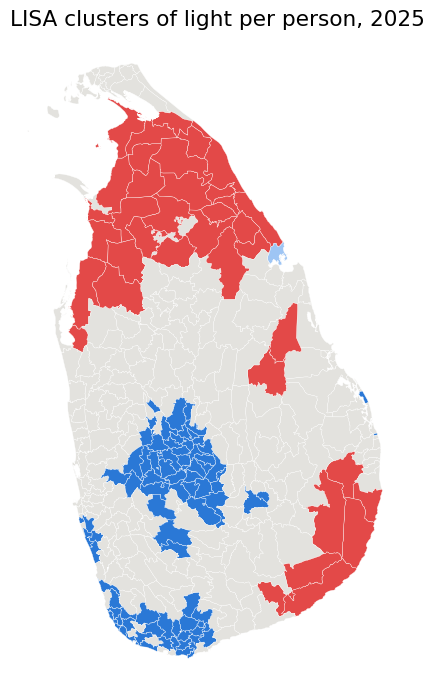

In [8]:
where = lisa_pc.df.merge(pc[pc["year"] == 2025][["geo_id", "province"]], on="geo_id")
print(pd.crosstab(where["province"], where["cluster"]))

gplot = gdf.copy()
gplot["geometry"] = gdf.to_crs(5235).simplify(150).to_crs(4326)
cl = gplot.merge(lisa_pc.df[["geo_id", "cluster"]], on="geo_id")
colours = {"High-High": "#e34948", "Low-Low": "#2a78d6", "High-Low": "#f2a7a6",
           "Low-High": "#9ec5f4", "Not significant": "#e3e2de"}
fig, ax = plt.subplots(figsize=(6, 8.5))
cl.plot(color=cl["cluster"].map(colours), edgecolor="white", linewidth=0.25, ax=ax)
ax.set_axis_off()
ax.set_title("LISA clusters of light per person, 2025", loc="left")
plt.savefig("fig_lisa_per_person_2025.png", dpi=200, bbox_inches="tight")
plt.show()

**Result:** the two measures give opposite pictures.
- **Light per km²:** one hot spot around Colombo; dimmer divisions catch up (β < 0)
  and the spread narrows.
- **Light per person:** hot spots in the sparsely populated North (16), North
  Central (8) and East (7); no catching up (β ≈ 0, R² 0.02) and the spread *widens*
  (0.62 → 0.73).

Light per person is high where few people live among roads, towns and street
lighting, and low in crowded areas such as the Central hills and the Southern coast.
Which measure reflects living standards better? Step P5 checks.

## Step P5 · Which measure tracks living standards? Check against HIES

Same checks as notebook 04, for both measures at district level: levels in 2019
(spending, income, poverty) and change 2016→2019 (spending).

Note: the HIES tables are lined up with the light table by district name
(`reindex`) before correlating, so each district is compared with itself.

In [9]:
pc["light_x_area"] = pc["ntl_mean"] * pc["area_sqkm"]
dd = pc.groupby(["district", "year"]).agg(light_x_area=("light_x_area", "sum"),
                                          population=("population", "sum"), area=("area_sqkm", "sum"))
dd["light_pc"] = dd["light_x_area"] / dd["population"] * 1000
dd["light_density"] = dd["light_x_area"] / dd["area"]
lp, ld = dd["light_pc"].unstack(), dd["light_density"].unstack()

h19 = hies2019.reindex(lp.index)          # line up districts by name
h16 = hies2016.reindex(lp.index)
print("Districts lined up:", h19.notna().all(axis=1).sum(), "of", len(lp))     # 25 of 25

rows = []
for label, L in [("Light per km²", ld), ("Light per person", lp)]:
    rows.append({"measure": label,
        "spending 2019": round(stats.pearsonr(np.log(L[2019]), np.log(h19["hh_expenditure"]))[0], 2),
        "income 2019":   round(stats.pearsonr(np.log(L[2019]), np.log(h19["mean_income"]))[0], 2),
        "poverty 2019":  round(stats.pearsonr(np.log(L[2019]), h19["mpi_headcount"])[0], 2),
        "change 2016→2019": round(stats.pearsonr(np.log(L[2019] / L[2016]),
                                  np.log(h19["hh_expenditure"] / h16["hh_expenditure"]))[0], 2)})
validity = pd.DataFrame(rows).set_index("measure")
validity.to_csv("check_density_vs_per_person.csv")
validity

Districts lined up: 25 of 25


,spending 2019,income 2019,poverty 2019,change 2016→2019
measure,,,,
Light per km²,0.81,0.77,-0.60,-0.29
Light per person,-0.33,-0.18,-0.08,-0.33


**Result:**

| | spending 2019 | income 2019 | poverty 2019 | change 2016→2019 |
|---|---|---|---|---|
| Light per km² | 0.81 | 0.77 | −0.60 | −0.29 |
| Light per person | −0.33 | −0.18 | −0.08 | −0.33 |

Light per km² tracks household living standards across districts; light per person
does not (it even has the wrong sign). Neither measure follows *changes* in spending
over 2016–2019.

**Conclusion:** for Sri Lanka, light per km² is the better measure of economic
activity, so the main results stay in light per km². The light-per-person results
show that the convergence finding **depends on how light is normalised**: a
limitation to report, and a reason to read the convergence results as convergence
*in light*, not yet in living standards.

In [10]:
from google.colab import files
for f in ["ds_population_2024.csv", "district_population_2012_2024.csv", "lka_ds339_ntl_annual_pc.csv",
          "compare_density_vs_per_person.csv", "check_density_vs_per_person.csv",
          "fig_lisa_per_person_2025.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>